In [24]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import metrics 
from sklearn import preprocessing
from sklearn import ensemble
from sklearn import tree
from sklearn.model_selection import train_test_split


In [2]:
data =pd.read_csv("car_evaluation.csv")
data

,vhigh,vhigh.1,2,2.1,small,low,unacc
0,vhigh,vhigh,2,2,small,med,unacc
1,vhigh,vhigh,2,2,small,high,unacc
2,vhigh,vhigh,2,2,med,low,unacc
3,vhigh,vhigh,2,2,med,med,unacc
4,vhigh,vhigh,2,2,med,high,unacc
...,...,...,...,...,...,...,...
1722,low,low,5more,more,med,med,good
1723,low,low,5more,more,med,high,vgood
1724,low,low,5more,more,big,low,unacc
1725,low,low,5more,more,big,med,good


In [3]:
cols = [ "buying","maint" , "doors" ,"persons" , "lug_boot" ,  "safty" , "class"]

data.columns = cols
data

,buying,maint,doors,persons,lug_boot,safty,class
0,vhigh,vhigh,2,2,small,med,unacc
1,vhigh,vhigh,2,2,small,high,unacc
2,vhigh,vhigh,2,2,med,low,unacc
3,vhigh,vhigh,2,2,med,med,unacc
4,vhigh,vhigh,2,2,med,high,unacc
...,...,...,...,...,...,...,...
1722,low,low,5more,more,med,med,good
1723,low,low,5more,more,med,high,vgood
1724,low,low,5more,more,big,low,unacc
1725,low,low,5more,more,big,med,good


In [4]:
data.head()

,buying,maint,doors,persons,lug_boot,safty,class
0,vhigh,vhigh,2,2,small,med,unacc
1,vhigh,vhigh,2,2,small,high,unacc
2,vhigh,vhigh,2,2,med,low,unacc
3,vhigh,vhigh,2,2,med,med,unacc
4,vhigh,vhigh,2,2,med,high,unacc


In [5]:
data.tail()

,buying,maint,doors,persons,lug_boot,safty,class
1722,low,low,5more,more,med,med,good
1723,low,low,5more,more,med,high,vgood
1724,low,low,5more,more,big,low,unacc
1725,low,low,5more,more,big,med,good
1726,low,low,5more,more,big,high,vgood


In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1727 entries, 0 to 1726
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   buying    1727 non-null   str  
 1   maint     1727 non-null   str  
 2   doors     1727 non-null   str  
 3   persons   1727 non-null   str  
 4   lug_boot  1727 non-null   str  
 5   safty     1727 non-null   str  
 6   class     1727 non-null   str  
dtypes: str(7)
memory usage: 133.4 KB


In [7]:
data.shape

(1727, 7)

In [8]:
data.isnull().sum()

buying      0
maint       0
doors       0
persons     0
lug_boot    0
safty       0
class       0
dtype: int64

In [9]:
data.duplicated().sum()

np.int64(0)

In [10]:


# فرض کنیم نام دیتافریم شما df است:
for col in data.columns:
    print(f"=== Value counts for: {col} ===")
    print(data[col].value_counts())
    print("-" * 35)  # برای جدا کردن خروجی‌ها


=== Value counts for: buying ===
buying
high     432
med      432
low      432
vhigh    431
Name: count, dtype: int64
-----------------------------------
=== Value counts for: maint ===
maint
high     432
med      432
low      432
vhigh    431
Name: count, dtype: int64
-----------------------------------
=== Value counts for: doors ===
doors
3        432
4        432
5more    432
2        431
Name: count, dtype: int64
-----------------------------------
=== Value counts for: persons ===
persons
4       576
more    576
2       575
Name: count, dtype: int64
-----------------------------------
=== Value counts for: lug_boot ===
lug_boot
med      576
big      576
small    575
Name: count, dtype: int64
-----------------------------------
=== Value counts for: safty ===
safty
med     576
high    576
low     575
Name: count, dtype: int64
-----------------------------------
=== Value counts for: class ===
class
unacc    1209
acc       384
good       69
vgood      65
Name: count, dtype: int64
-

In [11]:
for c in cols :
    print(data[c].value_counts())
    print("----------------------------------------------------")

buying
high     432
med      432
low      432
vhigh    431
Name: count, dtype: int64
----------------------------------------------------
maint
high     432
med      432
low      432
vhigh    431
Name: count, dtype: int64
----------------------------------------------------
doors
3        432
4        432
5more    432
2        431
Name: count, dtype: int64
----------------------------------------------------
persons
4       576
more    576
2       575
Name: count, dtype: int64
----------------------------------------------------
lug_boot
med      576
big      576
small    575
Name: count, dtype: int64
----------------------------------------------------
safty
med     576
high    576
low     575
Name: count, dtype: int64
----------------------------------------------------
class
unacc    1209
acc       384
good       69
vgood      65
Name: count, dtype: int64
----------------------------------------------------


In [12]:
orders = [
    ["low", "med", "high", "vhigh"],
    ["low", "med", "high", "vhigh"],
    ["2", "3", "4", "5more"],
    ["2", "4", "more"],                # <--- اینجا 'more' جایگزین '5more' شد
    ["small", "med", "big"],
    ["low", "med", "high"],
    ["unacc", "acc", "good", "vgood"]
]



In [13]:
oe =preprocessing.OrdinalEncoder(categories=orders)
data = pd.DataFrame(oe.fit_transform(data).astype("int"), columns=cols) 
data

,buying,maint,doors,persons,lug_boot,safty,class
0,3,3,0,0,0,1,0
1,3,3,0,0,0,2,0
2,3,3,0,0,1,0,0
3,3,3,0,0,1,1,0
4,3,3,0,0,1,2,0
...,...,...,...,...,...,...,...
1722,0,0,3,2,1,1,2
1723,0,0,3,2,1,2,3
1724,0,0,3,2,2,0,0
1725,0,0,3,2,2,1,2


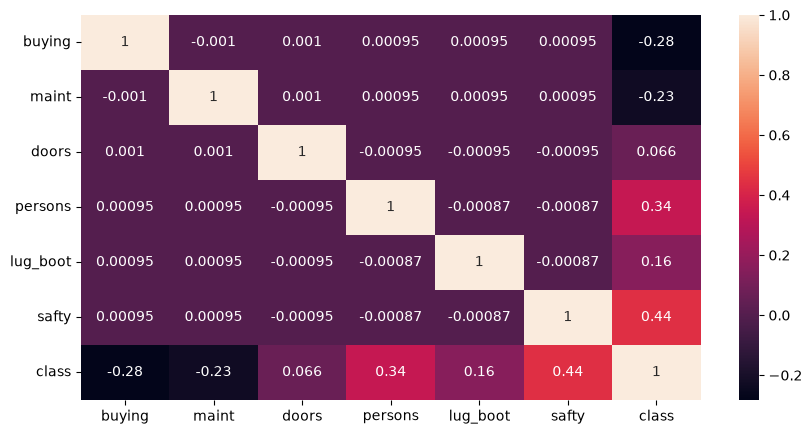

In [14]:
plt.figure(figsize=(10,5))
sns.heatmap(data.corr() , annot=True)
plt.show()

In [15]:
x =data.drop("class" , axis=1)
y = data["class"]





In [18]:
x_train , x_test , y_train , y_test =train_test_split(x , y , random_state=42 , test_size=0.2)

In [25]:
model_tree = tree.DecisionTreeClassifier()
model_tree.fit(x_train , y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [27]:
y_pred_tree = model_tree.predict(x_test)
metrics.accuracy_score(y_test , y_pred_tree)*100

96.53179190751445

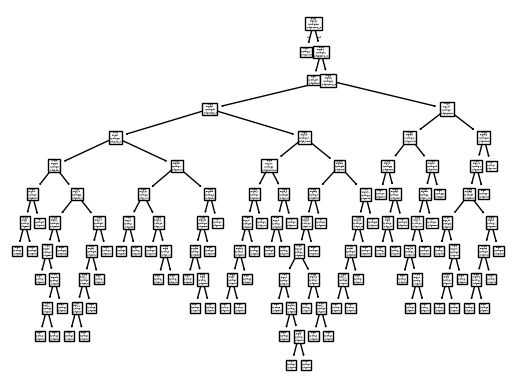

In [28]:
tree.plot_tree(model_tree)
plt.show()